## Stacked phase-diagram panel for the three SLN variants

One 18.4 x 15 cm figure made of three 18.4 x 5 cm rows, each row built exactly like the
"Journal-sized phase-diagram panel" cell of
`plot_phase_diagram_G_alpha_g_alpha_flat_recurrent_e_recurrent_hierarchy_trial3.ipynb`:
Prob(A) - Prob(B), then the number of persistent areas in Pop A and in Pop B, Open Sans at 7 pt.

Rows, top to bottom, are the datasets plotted by:

1. `plot_phase_diagram_G_alpha_g_alpha_sln05_rev.ipynb` -> `g_alpha_sln05_rev`
2. `plot_phase_diagram_G_alpha_g_alpha_sln05_recurrent_hierarchy.ipynb` -> `g_alpha_sln05_recurrent_hierarchy`
3. `plot_phase_diagram_G_alpha_g_alpha_sln04_recurrent_hierarchy.ipynb` -> `g_alpha_sln04_recurrent_hierarchy`

This notebook only reads those result CSVs; none of the existing notebooks are touched.


In [1]:
# Setup: same style and colormaps as the source notebooks, nothing is written to them.
import os

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import scienceplots
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import MaxNLocator

# The source notebooks all start from this style, so it is applied here too and then
# overridden by panel_style below, exactly as in the trial3 notebook.
plt.style.use(['science', 'nature'])

# Identical to cmaps_phase in all three source notebooks
cmaps_phase = {
    "pop_A": LinearSegmentedColormap.from_list(
        "pop_A", ["#ffffff", "#71ac8c", "#036330"], N=256
    ),
    "pop_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#ffffff", "#AF7885", "#ab1337"], N=256
    ),
    "pop_A_minus_B": LinearSegmentedColormap.from_list(
        "pop_B", ["#9e2440", "#ffffff", "#057b3c"], N=256
    ),
}

# Applied only inside the "with" block of the next cell.
# Note: the 'science' style sets text.usetex = True, and LaTeX ignores font.family, so
# usetex has to be off for Open Sans to be used. The mathtext entries make the $\alpha$
# in the x label and the $\Delta P$ colorbar label render in Open Sans too.
# figure.titlesize is the only addition to the style dict used in the trial3 notebook;
# it keeps the per-row titles at 7 pt as well.
panel_style = {
    "text.usetex": False,
    "font.family": "sans-serif",
    "font.sans-serif": ["Open Sans"],
    "mathtext.fontset": "custom",
    "mathtext.rm": "Open Sans",
    "mathtext.it": "Open Sans:italic",
    "mathtext.bf": "Open Sans:bold",
    "mathtext.cal": "Open Sans:italic",
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 7,
    "figure.titlesize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.major.size": 2,
    "ytick.major.size": 2,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
}


def style_ax(ax, nbins=4):
    ax.minorticks_off()
    ax.xaxis.set_major_locator(MaxNLocator(nbins))
    ax.yaxis.set_major_locator(MaxNLocator(nbins))
    ax.grid(which='major', linestyle=':', alpha=0.5)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.tick_params(top=False, right=False)


def style_cbar(cbar, nbins=4):
    cbar.locator = MaxNLocator(nbins)
    cbar.update_ticks()
    cbar.ax.minorticks_off()
    cbar.ax.tick_params(which='both', direction='out', length=2, width=0.8)


def load_stats(results_dir):
    """Read one persistent_activity_stats_all_runs.csv the same way the source notebooks do."""
    df = pd.read_csv(os.path.join(results_dir, 'persistent_activity_stats_all_runs.csv'),
                     delimiter=",", skipinitialspace=True)
    df = df[df['G'] <= 1.4]  # Simulation didn't work for some values above this

    # Probability(A) = Prob(A Only) + Prob(A & B), same for B, as in plot_forbidden_gap_analysis
    df["Probability(A)"] = df["Prob_A_Only"] + df["Prob_A_B"]
    df["Probability(B)"] = df["Prob_B_Only"] + df["Prob_A_B"]
    df["ProbDiff(A-B)"] = df["Probability(A)"] - df["Probability(B)"]
    return df


RESULTS_ROOT = '/home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results'

# One entry per row, top to bottom. Edit the labels here if different wording is wanted;
# they are the only text in the figure that is not taken from the source notebooks.
ROWS = [
    ('g_alpha_sln05_rev', 'SLN = 0.5'),
    ('g_alpha_sln05_recurrent_hierarchy', 'SLN = 0.5, recurrent hierarchy'),
    ('g_alpha_sln04_recurrent_hierarchy', 'SLN = 0.4, recurrent hierarchy'),
]

# The three maps of a row, left to right: column, title, colormap, colorbar label
MAPS = [
    ("ProbDiff(A-B)", "Prob(A) - Prob(B)", 'pop_A_minus_B', r'$\Delta P = P_a - P_b$'),
    ("MeanAreasA_uncond", "Pop A: No. of Persistent Areas", 'pop_A', None),
    ("MeanAreasB_uncond", "Pop B: No. of Persistent Areas", 'pop_B', None),
]

# The CSVs are large, so they are read once here and reused by the plotting cell
row_data = [(load_stats(os.path.join(RESULTS_ROOT, folder)), label) for folder, label in ROWS]
for (df_row, label), (folder, _) in zip(row_data, ROWS):
    print(f'{label:35s} {folder:40s} {len(df_row):6d} (G, alpha) points')


SLN = 0.5                           g_alpha_sln05_rev                         11830 (G, alpha) points
SLN = 0.5, recurrent hierarchy      g_alpha_sln05_recurrent_hierarchy         11830 (G, alpha) points
SLN = 0.4, recurrent hierarchy      g_alpha_sln04_recurrent_hierarchy         11830 (G, alpha) points


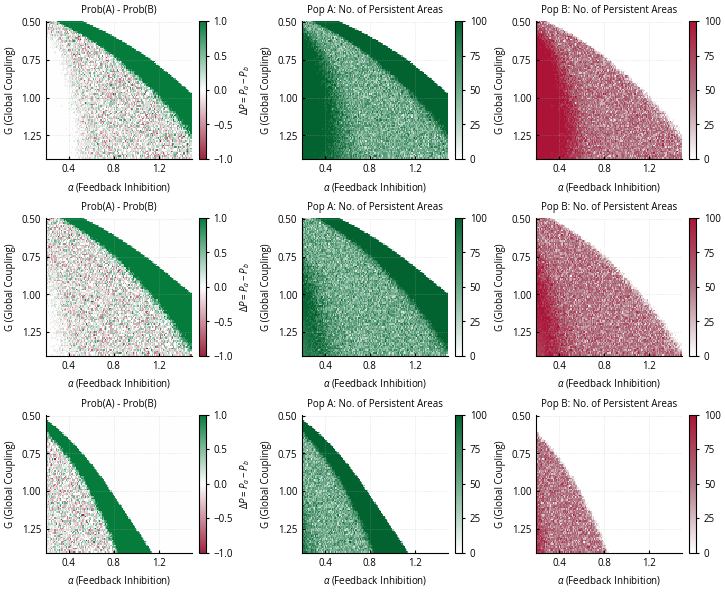

Panel is 18.4 x 15.0 cm, each row 18.4 x 5.0 cm
Saved in: /home/rad216/PhD_Projects/WM_human_merged/models/model_pet_nmda/results/combined_panels


In [4]:
# The stacked panel: 3 rows x 3 maps, 18.4 x 15 cm total (each row 18.4 x 5 cm).
# figsize is in inches, so divide the cm by 2.54
CM = 2.54
FIG_W = 18.4 / CM
FIG_H = 15.0 / CM
ROW_H = FIG_H / 3   # 5 cm per row

out_dir = os.path.join(RESULTS_ROOT, 'combined_panels')
os.makedirs(out_dir, exist_ok=True)

with mpl.rc_context(panel_style):
    # constrained_layout fits the titles and colorbars without changing the figure size.
    # subfigures keep each row self-contained, so a row can carry its own title.
    fig = plt.figure(figsize=(FIG_W, FIG_H), layout='constrained')
    subfigs = fig.subfigures(3, 1, hspace=0.0)

    for subfig, (df_row, row_label) in zip(np.atleast_1d(subfigs), row_data):
        # subfig.suptitle(row_label, fontweight='bold')
        axes = subfig.subplots(1, 3)

        for ax, (col, title, cmap_key, cbar_label) in zip(axes, MAPS):
            piv = df_row.pivot(index="G", columns="alpha", values=col)
            im = ax.pcolor(piv.columns, piv.index, piv.values,
                           cmap=cmaps_phase[cmap_key], shading='auto')
            ax.invert_yaxis()
            ax.set_title(title)
            ax.set_xlabel("$\\alpha$ (Feedback Inhibition)")
            ax.set_ylabel("G (Global Coupling)")
            style_ax(ax, nbins=4)

            cbar = subfig.colorbar(im, ax=ax)
            if cbar_label:
                cbar.set_label(cbar_label)
            style_cbar(cbar, nbins=4)

    # no bbox_inches='tight', so the files keep the exact 18.4 x 15 cm size
    fig.savefig(os.path.join(out_dir, 'phase_diagram_sln_variants_panel.pdf'))
    fig.savefig(os.path.join(out_dir, 'phase_diagram_sln_variants_panel.svg'))
    plt.show()

print(f'Panel is {FIG_W*CM:.1f} x {FIG_H*CM:.1f} cm, each row {FIG_W*CM:.1f} x {ROW_H*CM:.1f} cm')
print('Saved in:', out_dir)
